In [1]:
from config_path import add_to_sys_path
add_to_sys_path()  # Call the function to add path

import numpy as np
from sympy.physics.wigner import wigner_3j,wigner_6j
import sympy as sy
from numpy import linalg as LA
from IPython.display import Latex,display
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
sns.set()
sns.set_palette('terrain')
from Energy_Levels import MoleculeLevels
np.set_printoptions(precision=5, suppress=True)
import time
from matplotlib.colors import TwoSlopeNorm

Added C:\Users\Arian\Code\Molecule-Structure\Source Code to sys.path


Ported 2026-10-25 to the current `Energy_Levels.MoleculeLevels` API (`fermion_or_boson='fermion', isotope='173'`, `M_sublevels`/`M_list`/`I_nuclei`/`S_electron` keywords). Old outputs are in git history.

In [2]:
import json
try:
    import ujson as uj
except ImportError:  # ujson is not installed in the structure env; stdlib json has the same load/dump API
    uj = json

def get_json_data(file_path,numpy=False,ujson=True):
    if '.json' not in file_path:
        file_path+='.json'
    with open(file_path, 'r') as f:
        if ujson:
            data = uj.load(f)
        else:
            data = json.load(f)
    if numpy:
        data = np.array(data)
    return data

def save_json_data(data,file_path,ujson=True):
    if type(data) is np.ndarray:
        data_save = data.tolist()
    else:
        data_save=data
    if '.json' not in file_path:
        file_path+='.json'
    with open(file_path,'w') as f:
        if ujson:
            uj.dump(data_save,f)
        else:
            json.dump(data_save,f)
    print('Data saved to', file_path)

In [3]:
# Bstep = 0.2
# Bz = np.arange(0,5+Bstep,Bstep)
Bz = np.linspace(1e-4,1,100)
Ez = np.linspace(0,250,2001)
# Estep = 0.01
# Ez = np.arange(0,80+Estep,Estep)
print(len(Ez),len(Bz))
print(len(Ez)*len(Bz))

2001 100
200100


In [4]:
state_dict = {}
eval_dict = {}
evec_dict = {}
PTV_dict = {}
N=1

M_range = np.arange(1/2,9/2+1,1)
# M_range=[-1,1]
for M in M_range:
    M_state = MoleculeLevels.initialize_state('YbOH','X','010',[N],fermion_or_boson='fermion',isotope='173',M_sublevels='custom',M_list=[M],I_nuclei=[5/2,1/2],S_electron=1/2,round=10,P_values=[1/2,3/2],trap=False)
    state_dict[M] = M_state
    print(M)
    t0 = time.perf_counter()
    Eslices = M_state.EB_grid(Ez,Bz,PTV=True,reverse=False,E_or_B_first='E',trap_shifts=False,output=True,evecs=False,EDM_or_MQM='MQM')
    t1 = time.perf_counter()
    elapsed = t1 - t0
    print(elapsed, 'sec\n')
    eval_dict[M] = Eslices[0]
    PTV_dict[M] = Eslices[1]
#     evec_dict[M] = Eslices[2]
mesh = np.array(np.meshgrid(Ez,Bz,indexing='ij'))

0.5


16.01372280000942 sec



1.5


14.082385600006091 sec

2.5


6.5304831999965245 sec

3.5


3.704143099996145 sec

4.5


3.0398074999975506 sec



In [5]:
read = False
date = '20220503'
folder = r'JSON_data/'
N=1

if read:
    state_dict = {}
    eval_dict = {}
    evec_dict = {}
    PTV_dict = {}
#     for M in range(-(N+1),N+2,1):
    for M in [-1,1]:
        M_state = MoleculeLevels.initialize_state('CaOH','40','X010',[N],M_values = 'custom',I=[0,1/2],S=1/2,round=10,M_range=[M],P_values=[1/2,3/2])
        state_dict[M] = M_state
        print(M)
        eval_dict[M] = get_json_data(folder+'X010_CaOH_N{}_M{}_EB_grid_evals_{}'.format(N,M,date),numpy=True)
        PTV_dict[M] = get_json_data(folder+'X010_CaOH_N{}_M{}_EB_grid_PTV_{}'.format(N,M,date),numpy=True)
        evec_dict[M] = get_json_data(folder+'X010_CaOH_N{}_M{}_EB_grid_evecs_{}'.format(N,M,date),numpy=True)
    mesh = get_json_data(folder+'X010_CaOH_N{}_EzBz_grid_{}'.format(N,date),numpy=True)

In [6]:
save=False
date = '20220503'
folder = r'JSON_data/'
N=N
if save:
    for M in eval_dict.keys():
            save_json_data(eval_dict[M].tolist(),folder+'X010_CaOH_N{}_M{}_EB_grid_evals_{}'.format(N,M,date))
            save_json_data(PTV_dict[M].tolist(),folder+'X010_CaOH_N{}_M{}_EB_grid_PTV_{}'.format(N,M,date))
            save_json_data(evec_dict[M].tolist(),folder+'X010_CaOH_N{}_M{}_EB_grid_evecs_{}'.format(N,M,date))
    mesh = np.array(np.meshgrid(Ez,Bz,indexing='ij'))
    save_json_data(mesh.tolist(),folder+'X010_CaOH_N{}_EzBz_grid_{}'.format(N,date))
Ez = mesh[0,:,0]
Bz = mesh[1,0,:]

**Not run (port, 2026-10-25).** Reload of a saved CaOH grid: `JSON_data/X010_CaOH_N1_EzBz_grid_20220503.json` is not in the repo, and it would overwrite the 173YbOH `mesh` computed above. Source kept unchanged.

0.5


C:\Users\Arian\AppData\Local\Temp\ipykernel_49984\2820434963.py:6: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure()


1.5


2.5


3.5


4.5


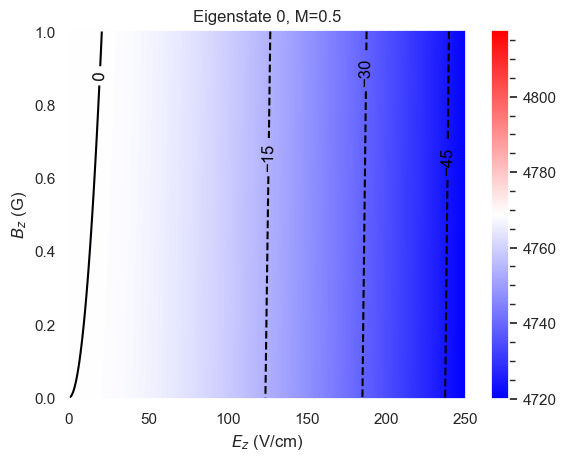

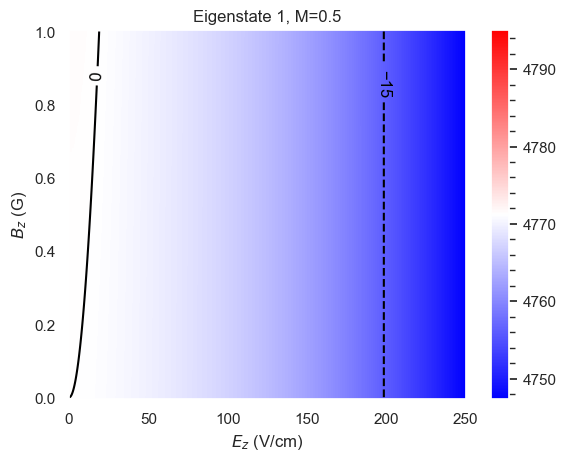

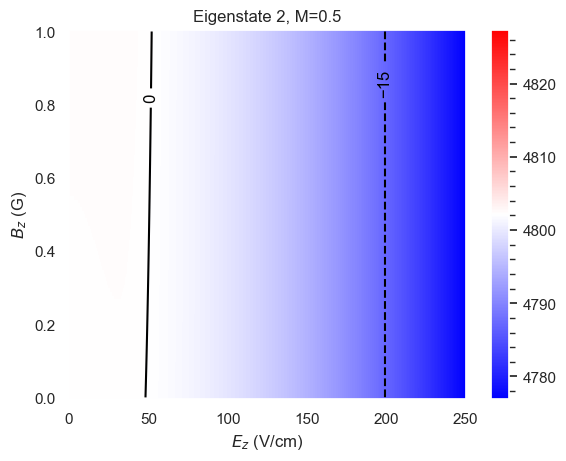

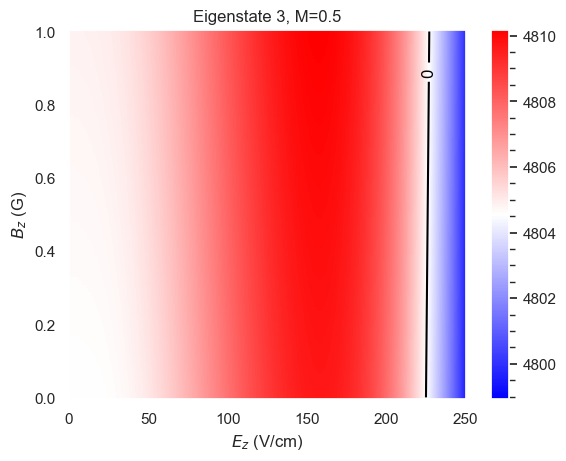

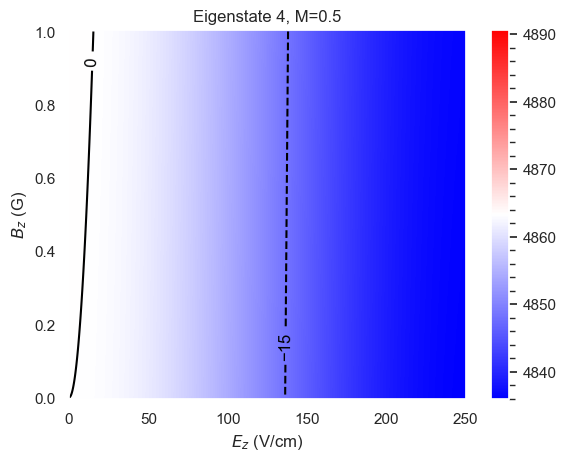

...

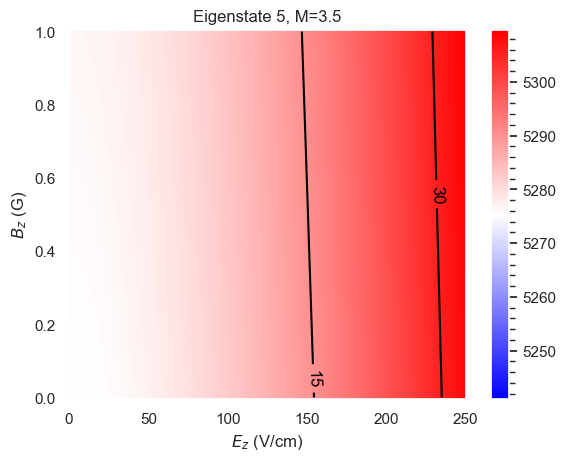

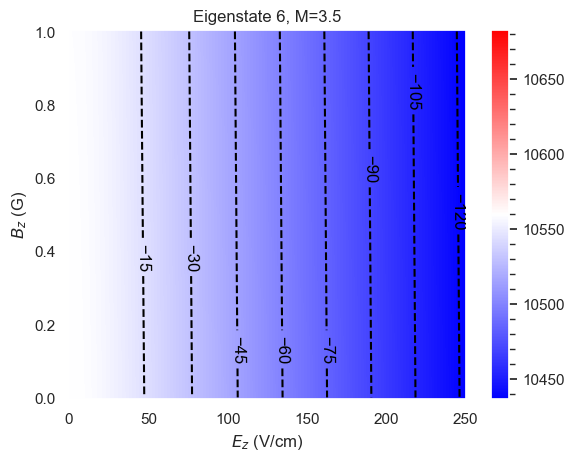

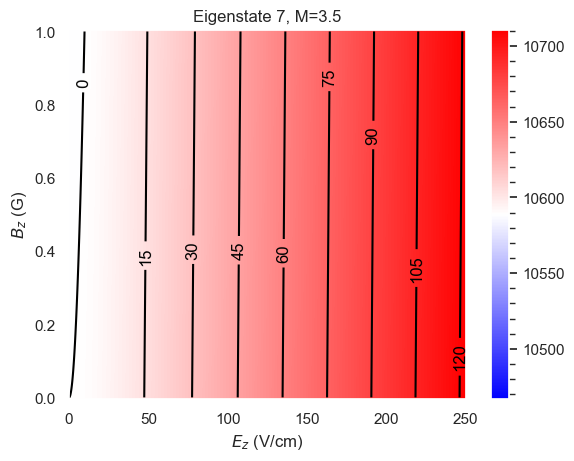

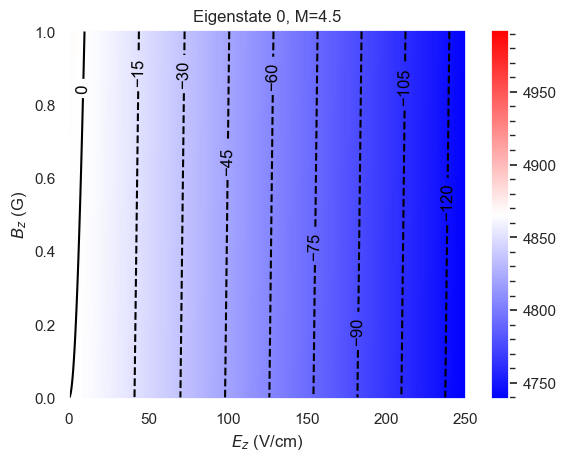

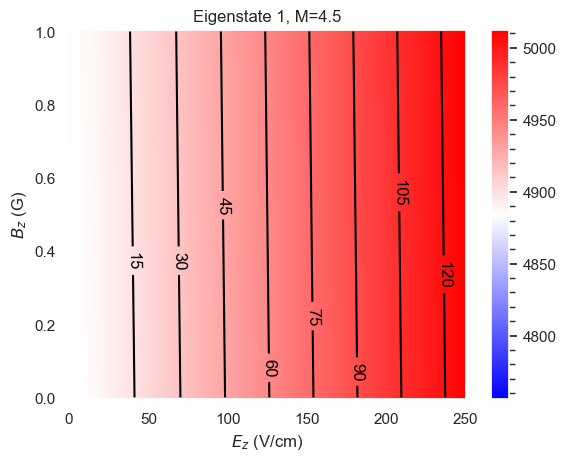

In [7]:
with_contour=True
for M in eval_dict.keys():
    print(M)
    evals_EB = eval_dict[M]
    for i in range(len(evals_EB)):
        plt.figure()
        E0 = evals_EB[i][0,0]
        max_delta = max(abs(evals_EB[i].max()-E0),abs(evals_EB[i].min()-E0))
        plt.grid(False)
        plt.pcolormesh(*mesh,evals_EB[i],shading='auto',cmap='bwr',norm=TwoSlopeNorm(vcenter=E0,vmin=E0-max_delta,vmax=E0+max_delta))
        cbar = plt.colorbar()
        cbar.minorticks_on()
        plt.title('Eigenstate {}, M={}'.format(i,M))
        plt.xlabel(r'$E_z$ (V/cm)')
        plt.ylabel(r'$B_z$ (G)')
        if with_contour:
            try:
                conmap = plt.contour(*mesh,evals_EB[i]-E0,colors='black',levels=np.linspace(-150,150,21))#norm=TwoSlopeNorm(vmin=-1,vcenter=0,vmax=1))
                plt.clabel(conmap, inline=True, fontsize=12)
    #             cbar = plt.colorbar()
    #             cbar.minorticks_on()
            except ValueError:
                print("Can't plot this data")

0.5


C:\Users\Arian\AppData\Local\Temp\ipykernel_49984\1408416203.py:6: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure()


1.5


2.5


3.5
4.5


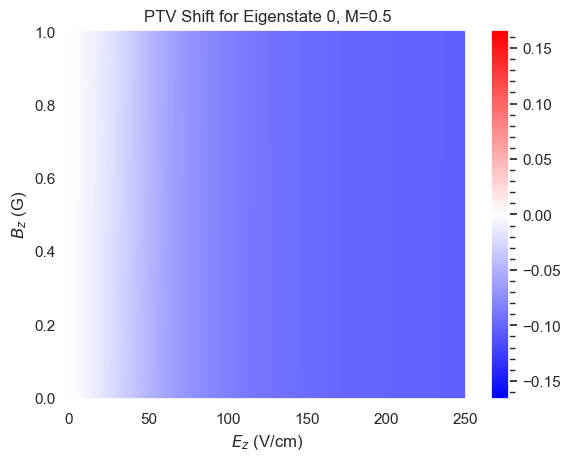

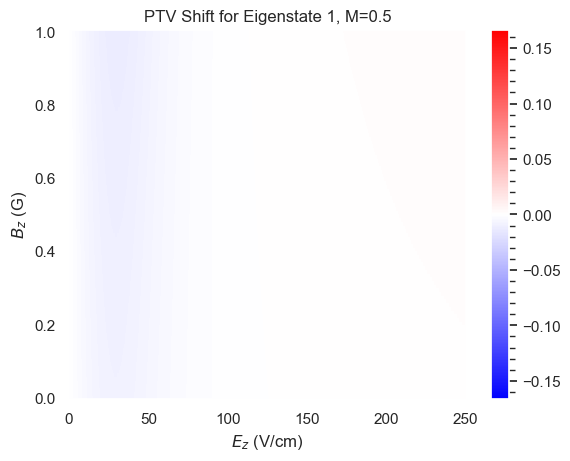

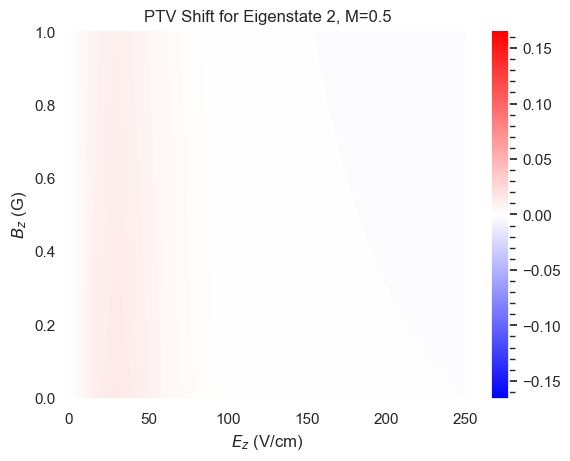

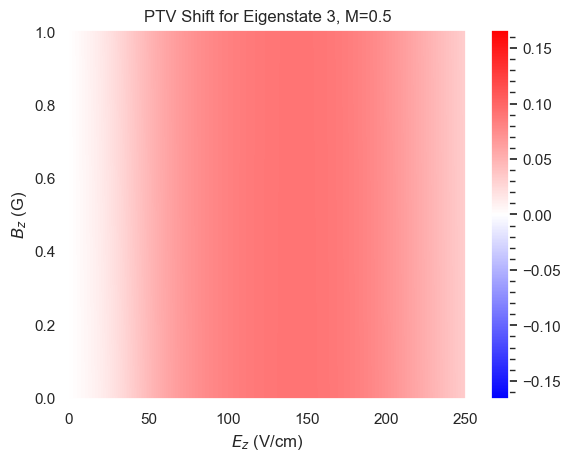

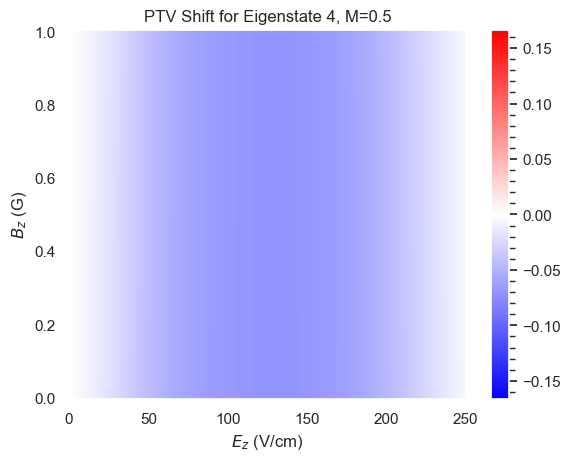

...

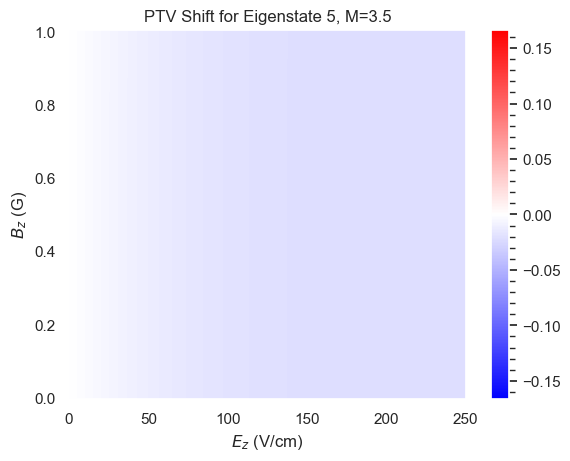

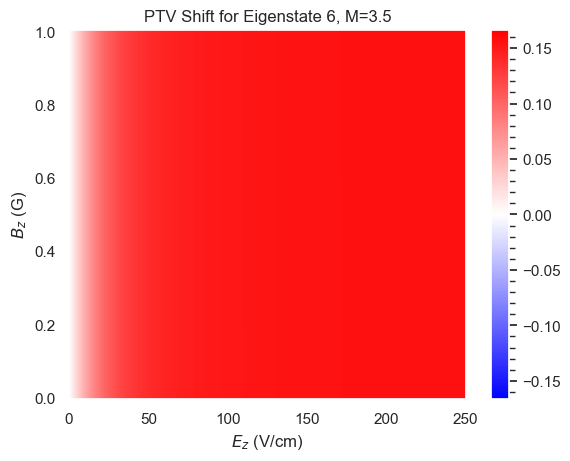

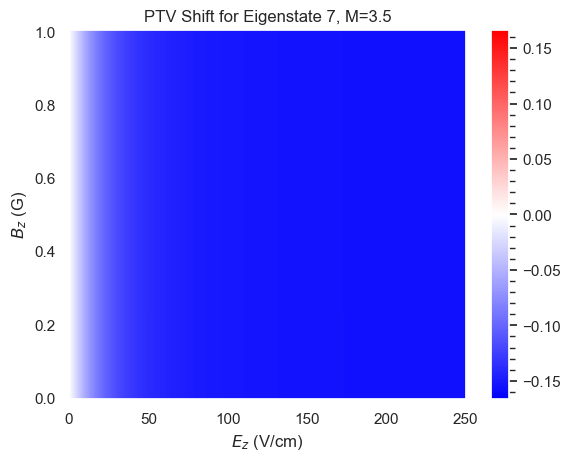

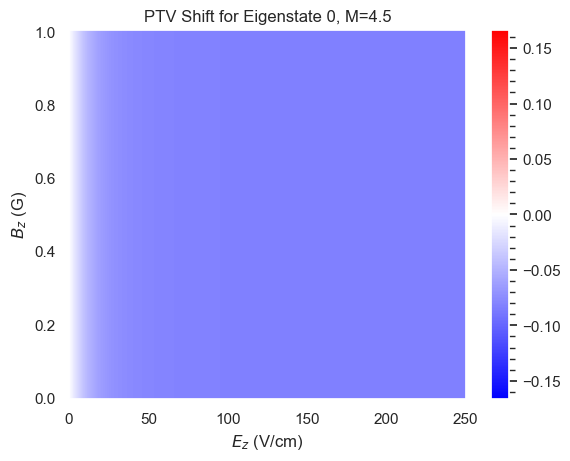

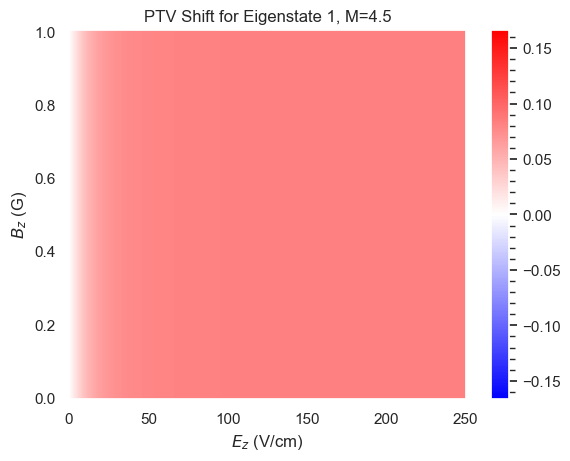

In [8]:
with_contour=False
for M in eval_dict.keys():
    print(M)
    PTV_EB = PTV_dict[M]
    for i in range(len(PTV_EB)):
        plt.figure()
        plt.grid(False)
        plt.pcolormesh(*mesh,PTV_EB[i],shading='auto',cmap='bwr',norm=TwoSlopeNorm(vcenter=0,vmin=-1/6,vmax=1/6))
        cbar = plt.colorbar()
        cbar.minorticks_on()
        plt.title('PTV Shift for Eigenstate {}, M={}'.format(i,M))
        plt.xlabel(r'$E_z$ (V/cm)')
        plt.ylabel(r'$B_z$ (G)')
        if with_contour:
            try:
                conmap = plt.contour(*mesh,PTV_EB[i],colors='black',levels=np.linspace(-1/6,1/6,11))#norm=TwoSlopeNorm(vmin=-1,vcenter=0,vmax=1))
                plt.clabel(conmap, inline=True, fontsize=12)
    #             cbar = plt.colorbar()
    #             cbar.minorticks_on()
            except ValueError:
                print("Can't plot this data")

**Not run (port to current API, 2026-10-25).** The raw cells below analyze an integer-M dataset (keys M = -2..2, e.g. `eval_dict[1]`, `eval_dict[-1]`, `state_dict[2]`; bBJ kets with I_H only), from an earlier run of this notebook on a different molecule/grid. This notebook now computes 173YbOH X(010) with M = 1/2..9/2 only (cell above), so these keys do not exist. Source kept unchanged; switch the cell type back to code once that dataset is defined.

In [9]:
(Bz[-1]-Bz[-2])

0.010099999999999998

0.5


C:\Users\Arian\AppData\Local\Temp\ipykernel_49984\1605719298.py:7: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(14,10))


1.5


2.5


3.5


4.5


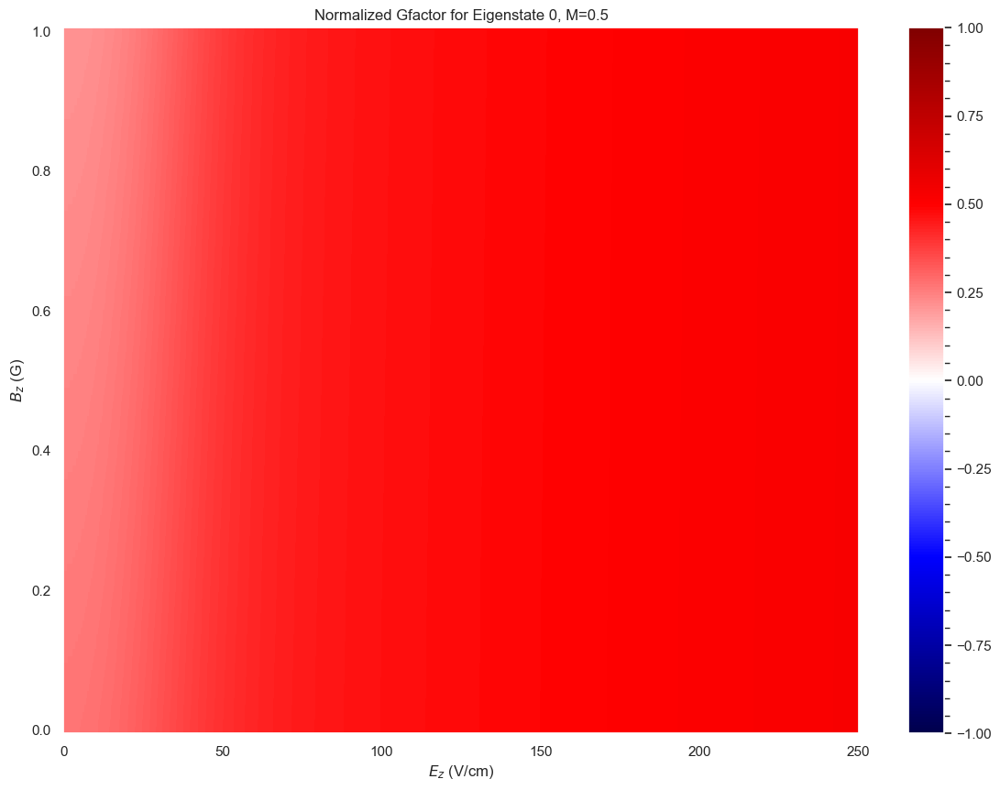

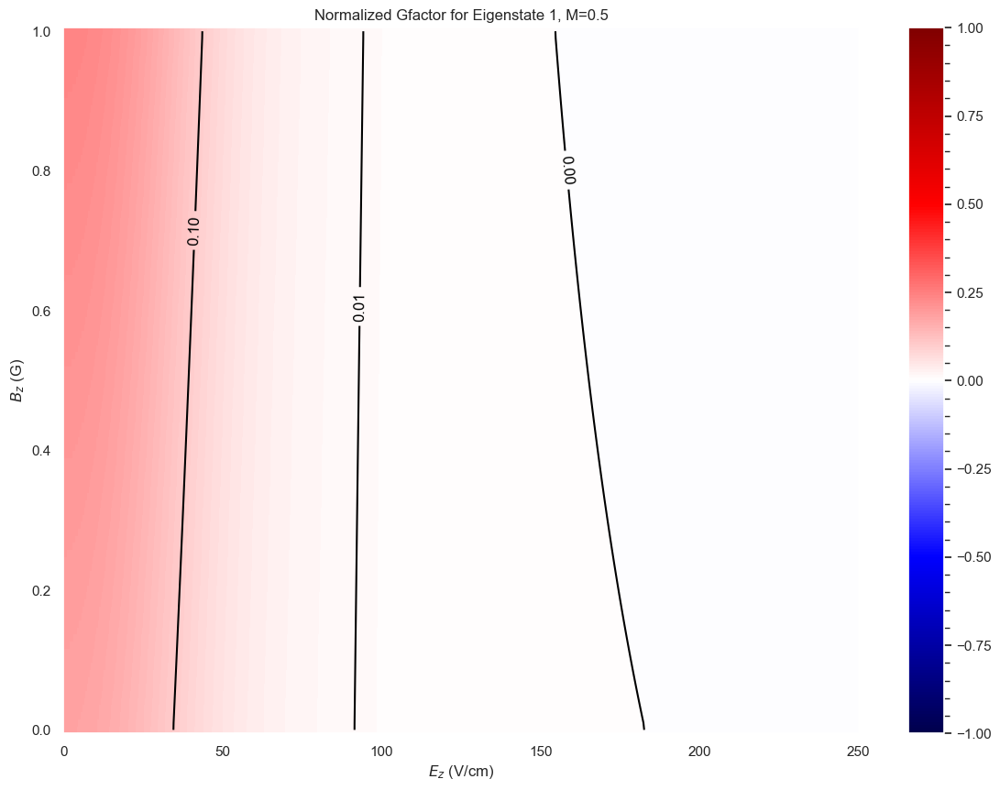

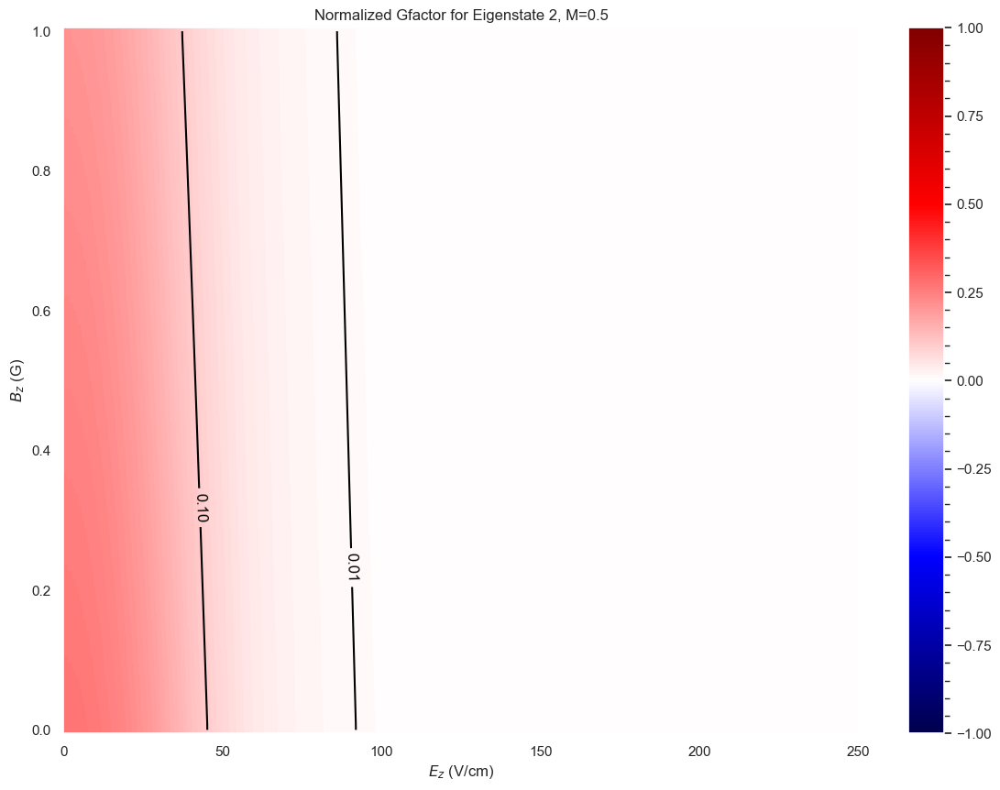

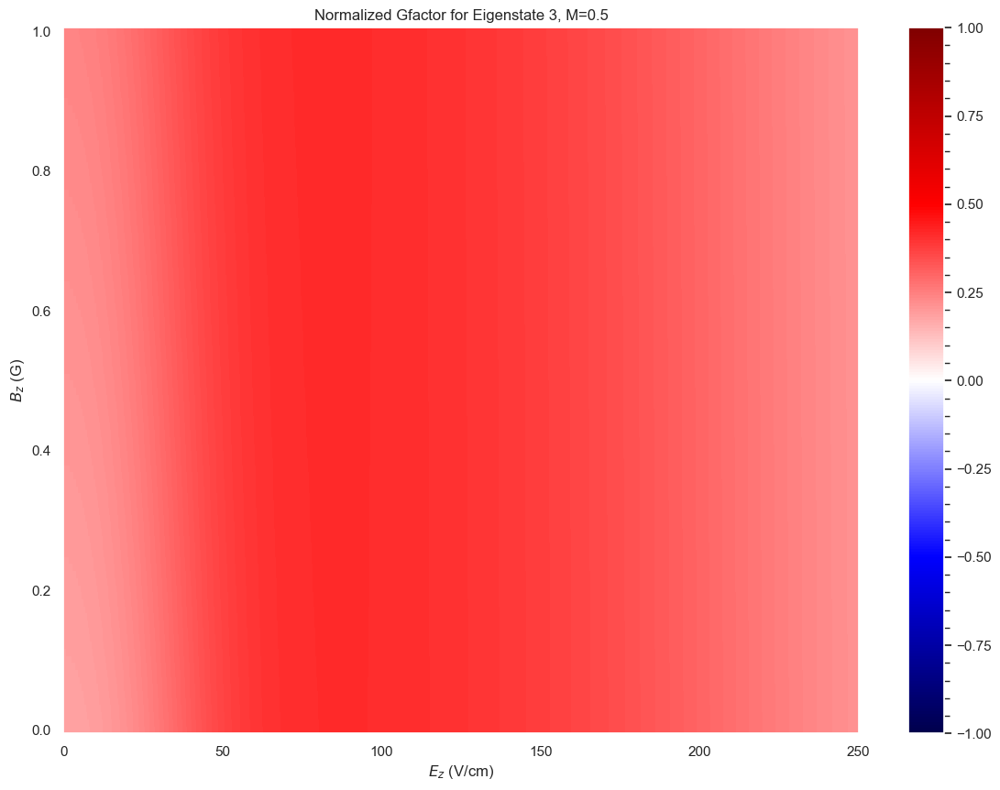

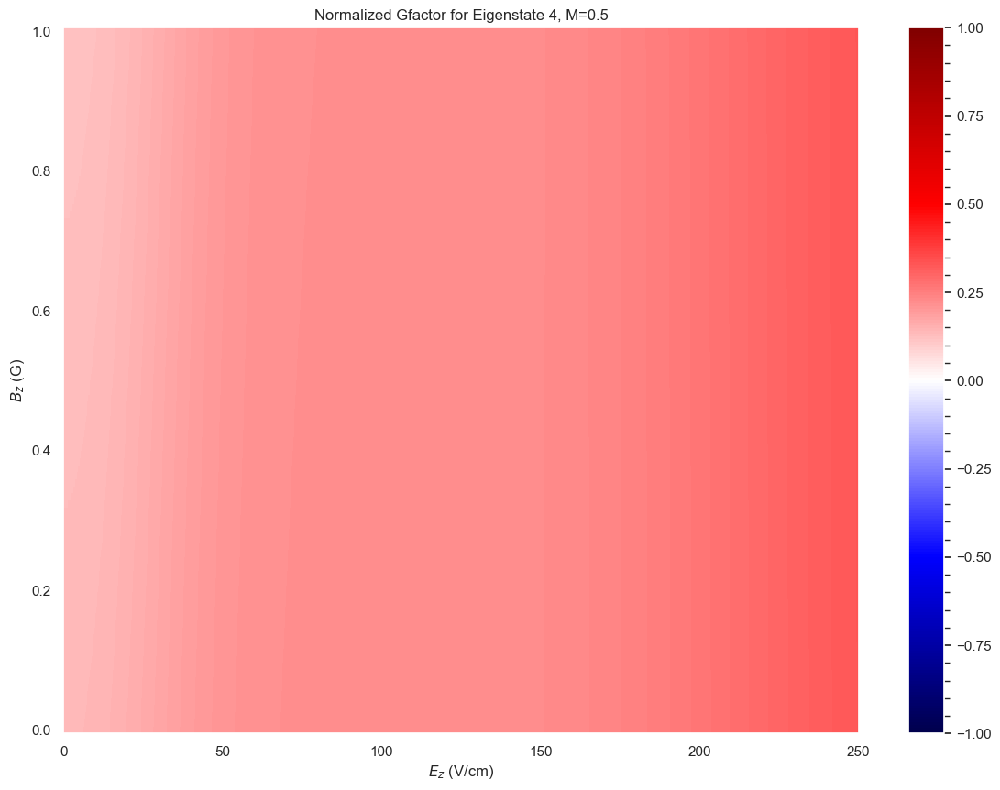

...

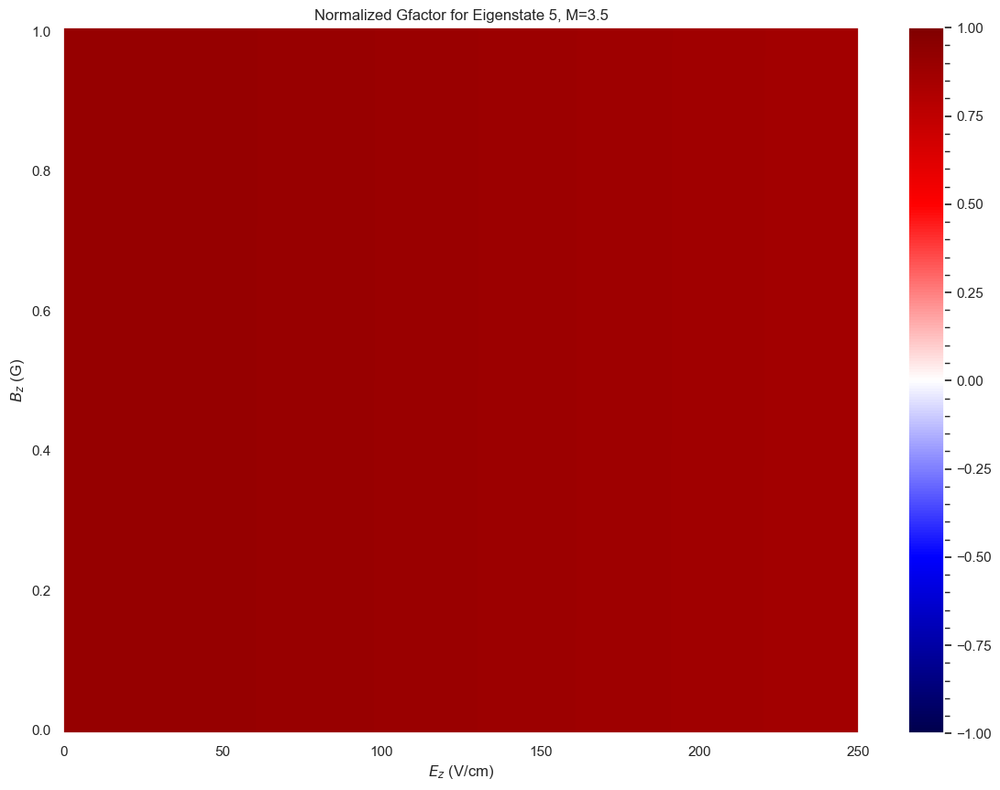

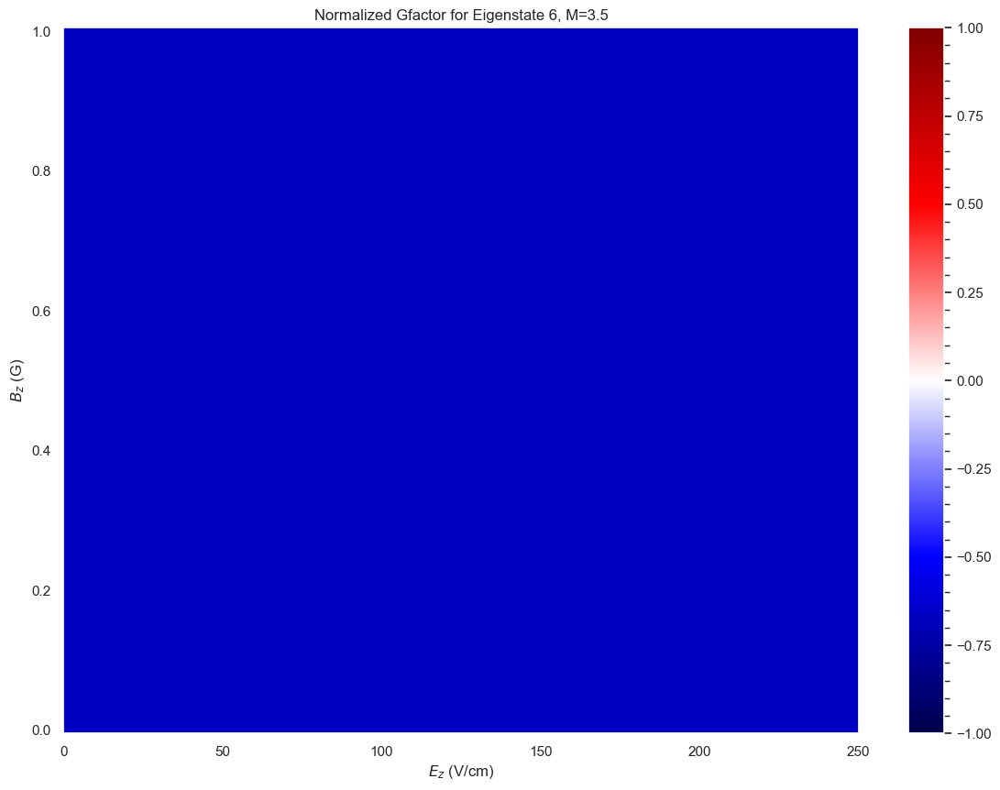

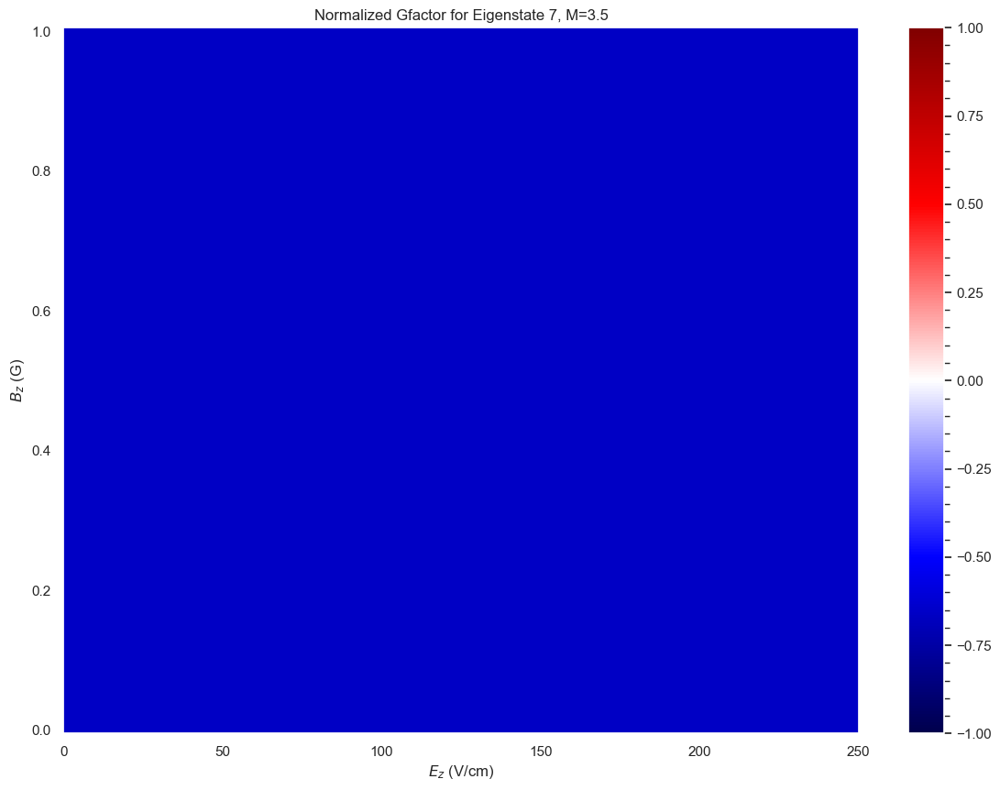

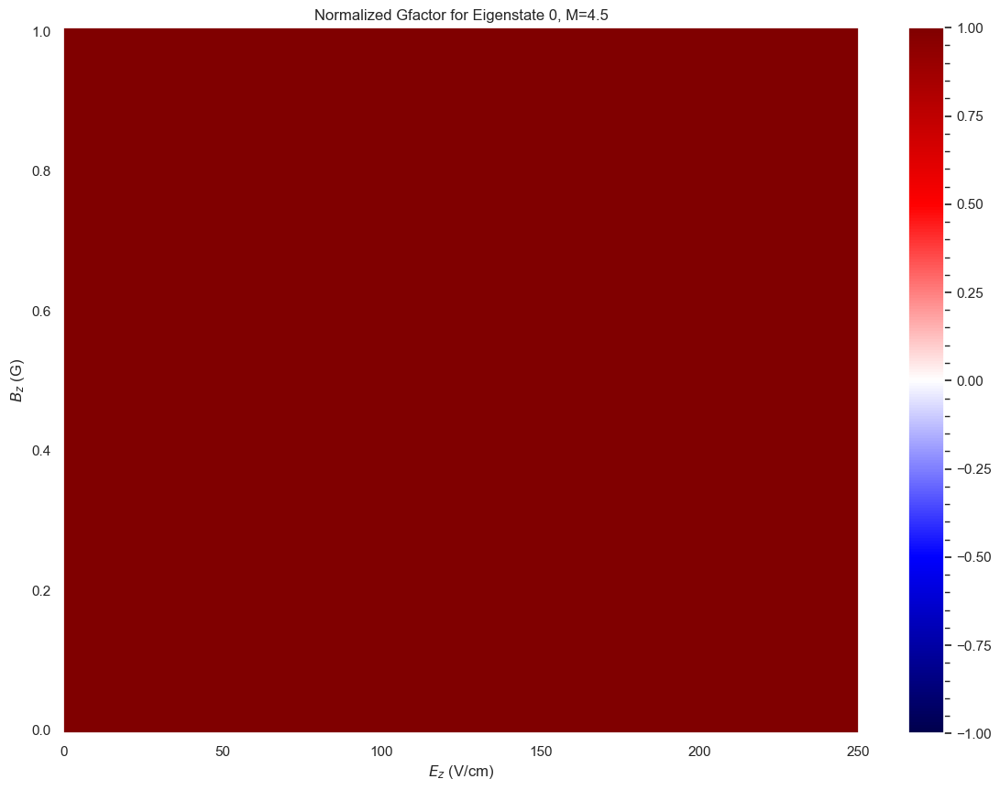

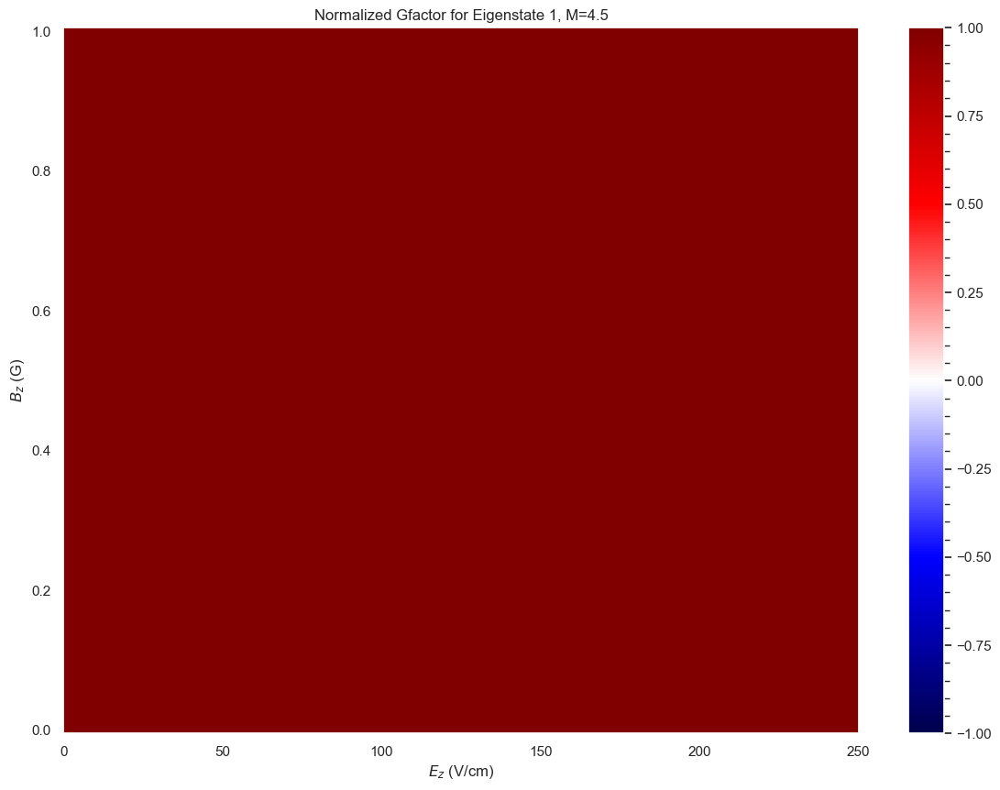

In [10]:
muBgS=1.399624494*2.0023/2
with_contour = True
for M in eval_dict.keys():
    print(M)
    evals_EB = eval_dict[M]
    for i in range(len(evals_EB)):
        plt.figure(figsize=(14,10))
        geff = np.gradient(evals_EB[i])[1]/abs(Bz[-1]-Bz[-2])
        plt.grid(False)
        plt.pcolormesh(*mesh,geff/muBgS,shading='auto',cmap='seismic',norm=TwoSlopeNorm(vmin=-1,vcenter=0,vmax=1))#,vmin=-1,vmax=1)
        cbar = plt.colorbar()
        cbar.minorticks_on()
        if with_contour:
            try:
                conmap = plt.contour(*mesh,geff/muBgS,colors='black',levels=[-0.1,-0.01,0,0.01,0.1],vmin=-0.1,vmax=0.1)#norm=TwoSlopeNorm(vmin=-1,vcenter=0,vmax=1))
                plt.clabel(conmap, inline=True, fontsize=12)
    #             cbar = plt.colorbar()
    #             cbar.minorticks_on()
            except ValueError:
                print("Can't plot this data")
#         if single:
#             geff_M = np.gradient(evals_M[i])[1]/abs(Bz[-1]-Bz[-2])
#             try:
#                 conmap = plt.contour(*mesh,geff_M/muBgS,colors='gold',levels=[0],vmin=-0.1,vmax=0.1)#norm=TwoSlopeNorm(vmin=-1,vcenter=0,vmax=1))
#                 plt.clabel(conmap, inline=True, fontsize=12)
#     #             cbar = plt.colorbar()
#     #             cbar.minorticks_on()
#             except ValueError:
#                 print("Can't plot this data")
        plt.title('Normalized Gfactor for Eigenstate {}, M={}'.format(i,M))
        plt.xlabel(r'$E_z$ (V/cm)')
        plt.ylabel(r'$B_z$ (G)')

**Not run (port to current API, 2026-10-25).** The raw cells below analyze an integer-M dataset (keys M = -2..2, e.g. `eval_dict[1]`, `eval_dict[-1]`, `state_dict[2]`; bBJ kets with I_H only), from an earlier run of this notebook on a different molecule/grid. This notebook now computes 173YbOH X(010) with M = 1/2..9/2 only (cell above), so these keys do not exist. Source kept unchanged; switch the cell type back to code once that dataset is defined.

0.5


C:\Users\Arian\AppData\Local\Temp\ipykernel_49984\4190423495.py:7: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(14,10))


1.5


2.5


3.5


4.5


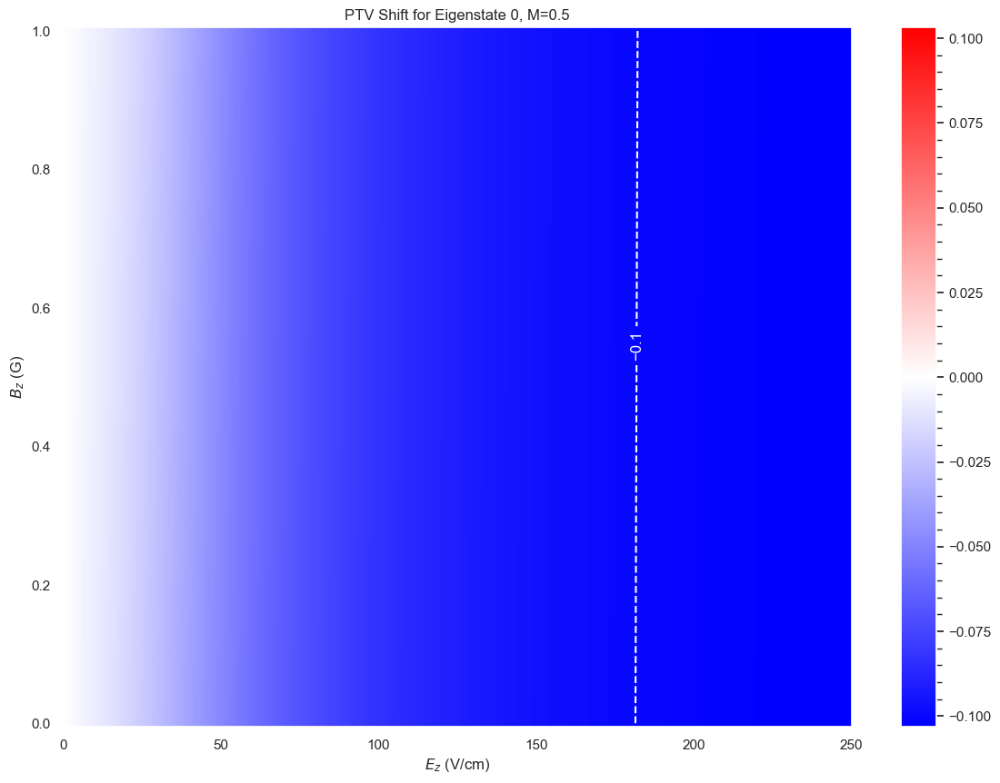

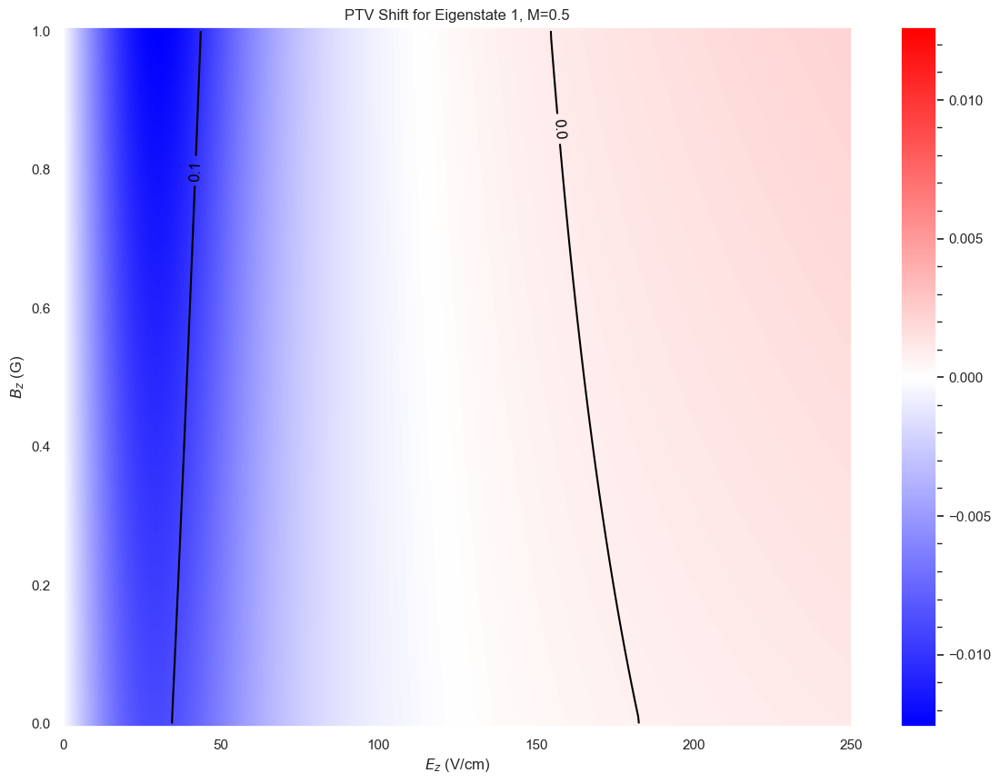

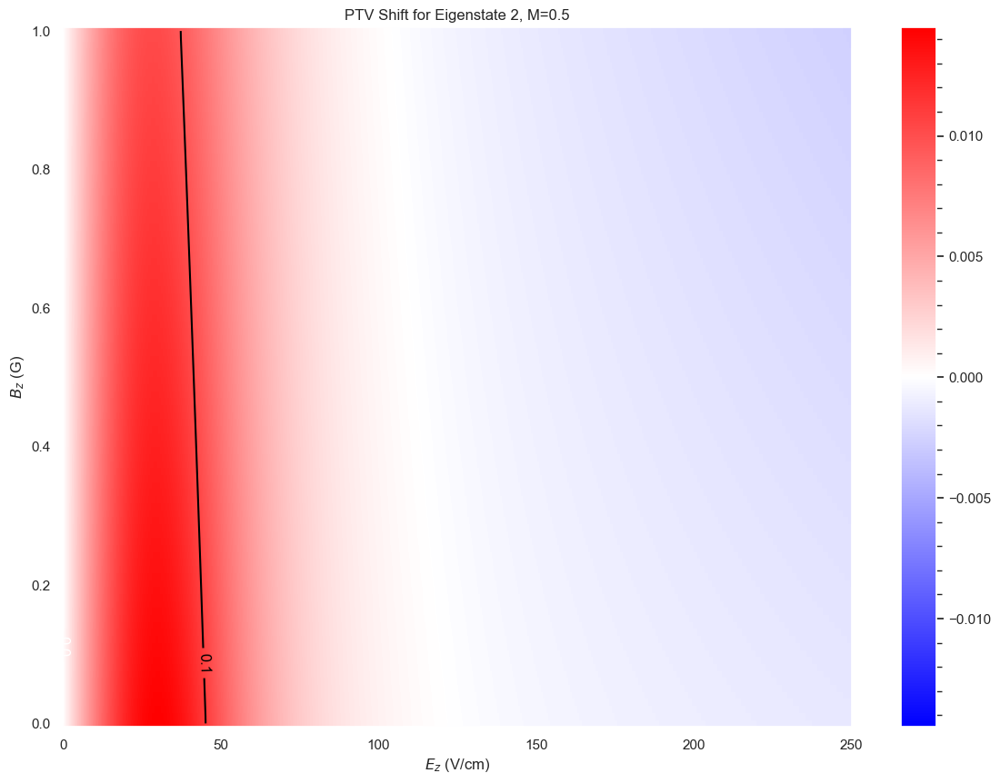

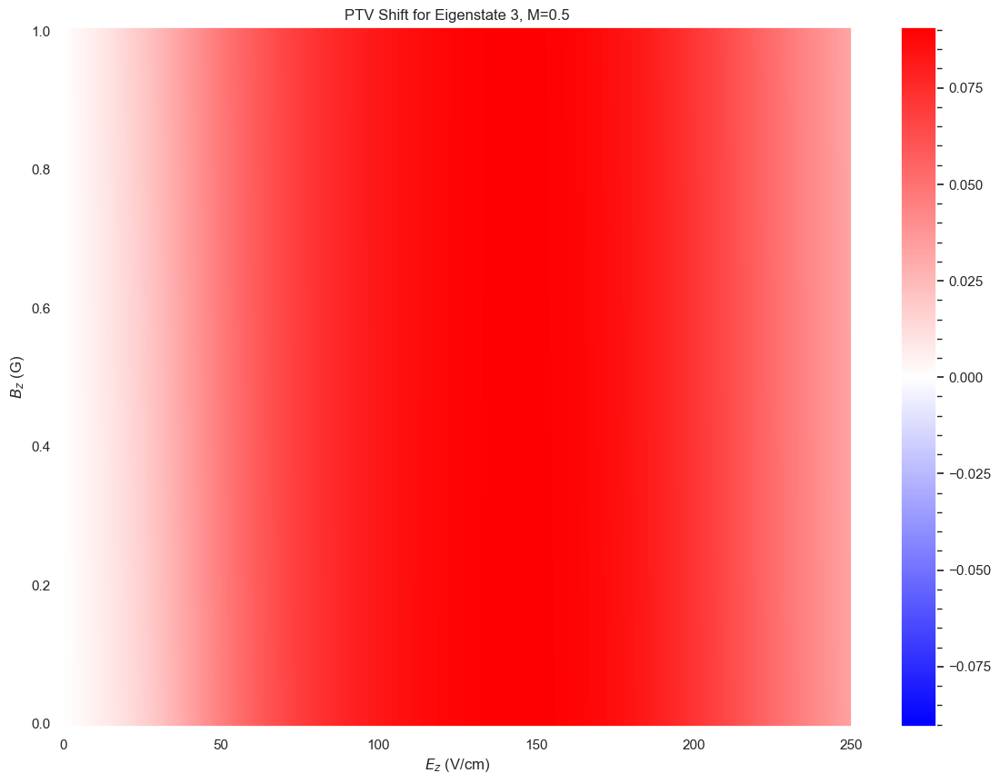

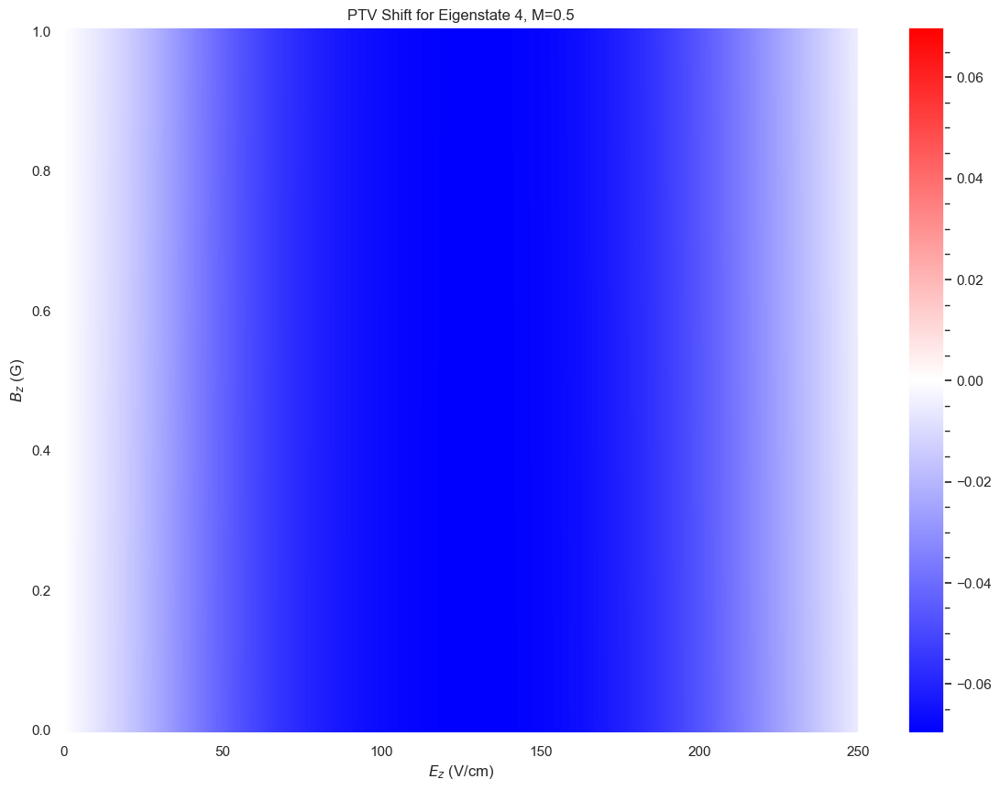

...

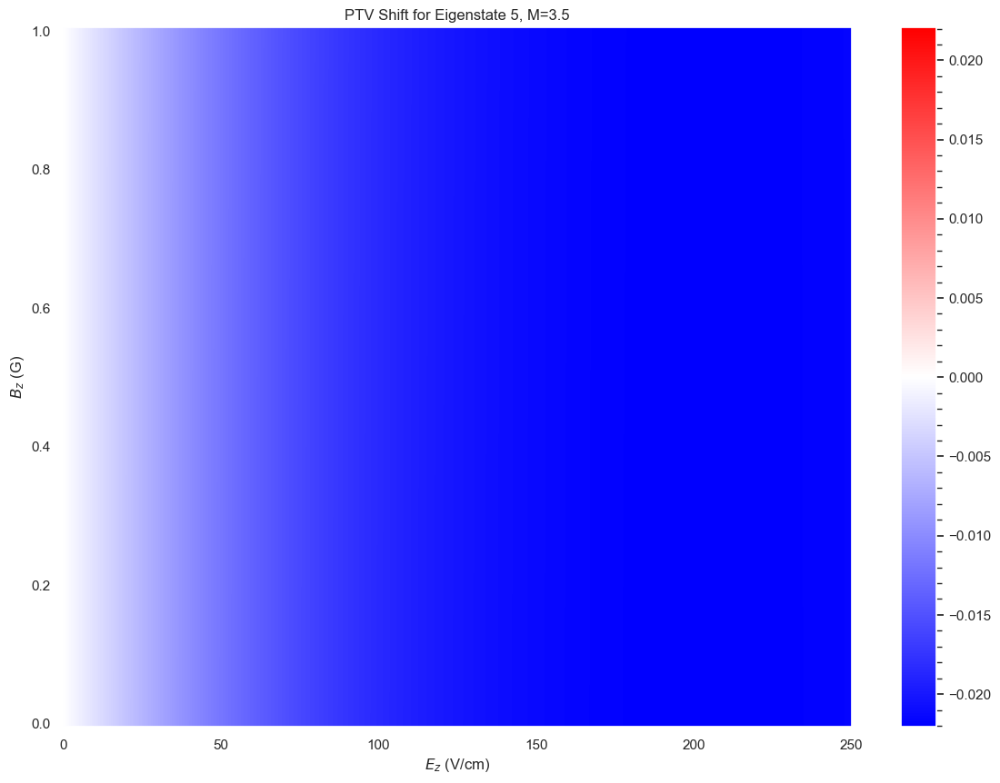

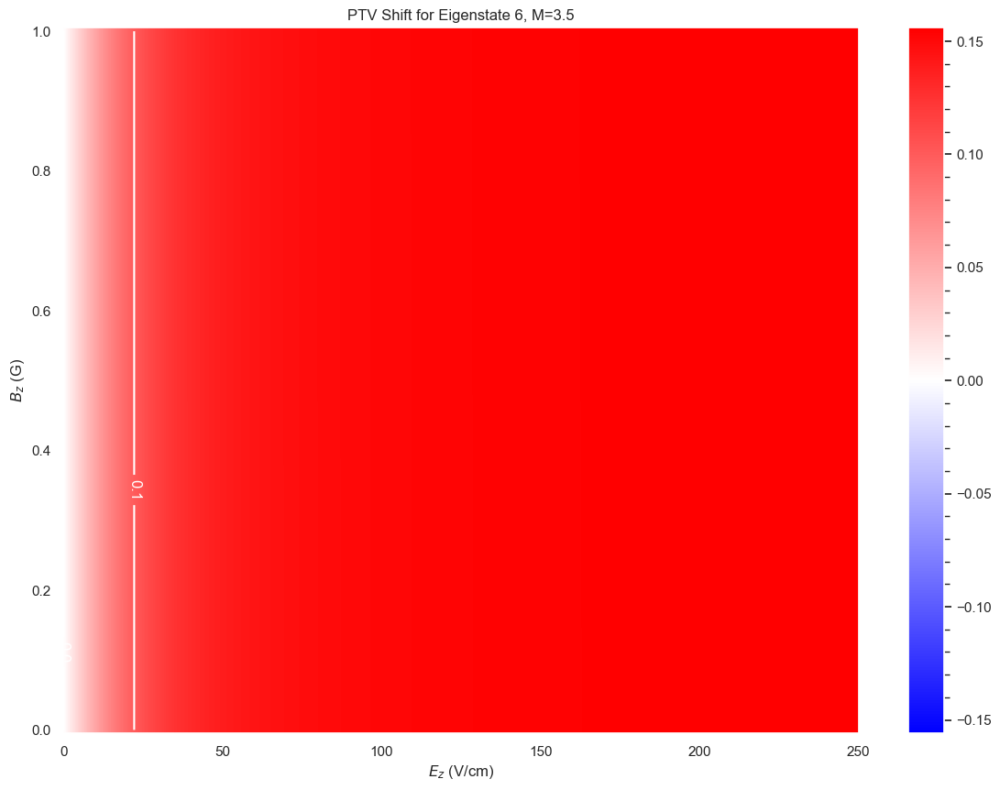

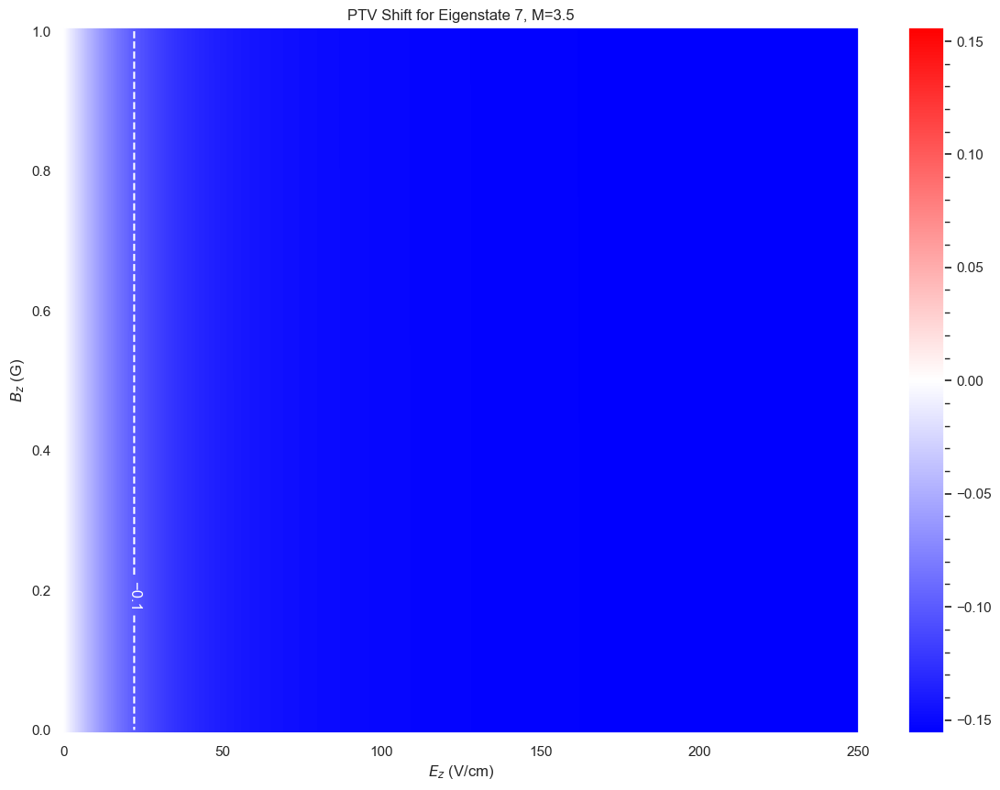

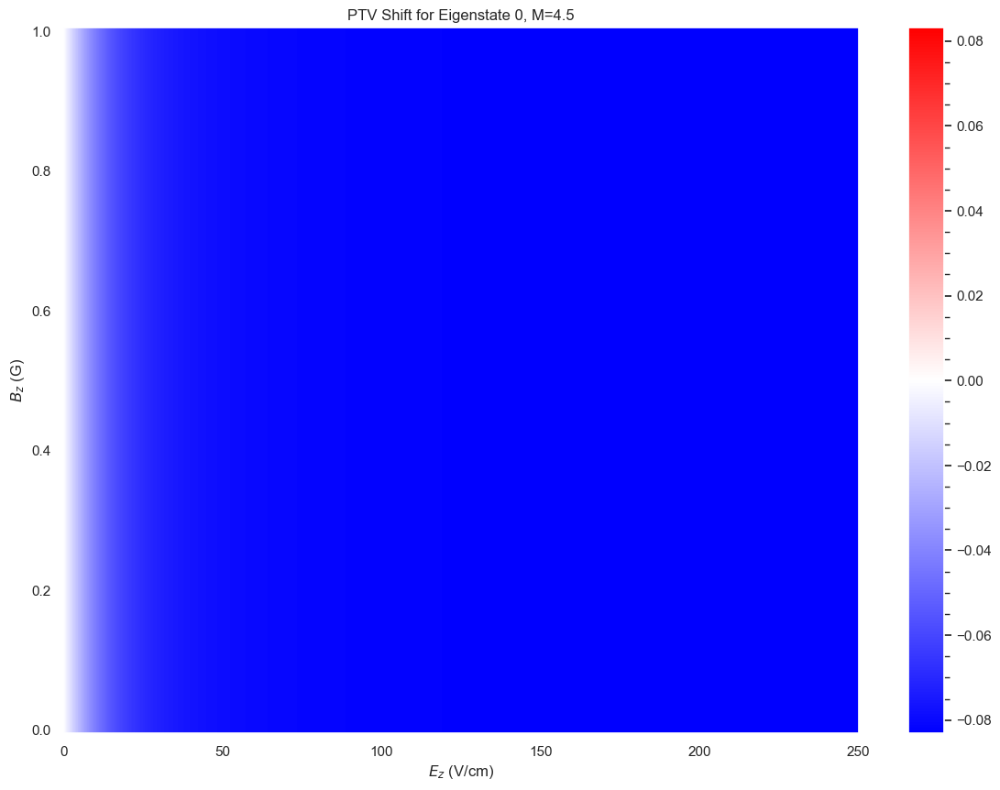

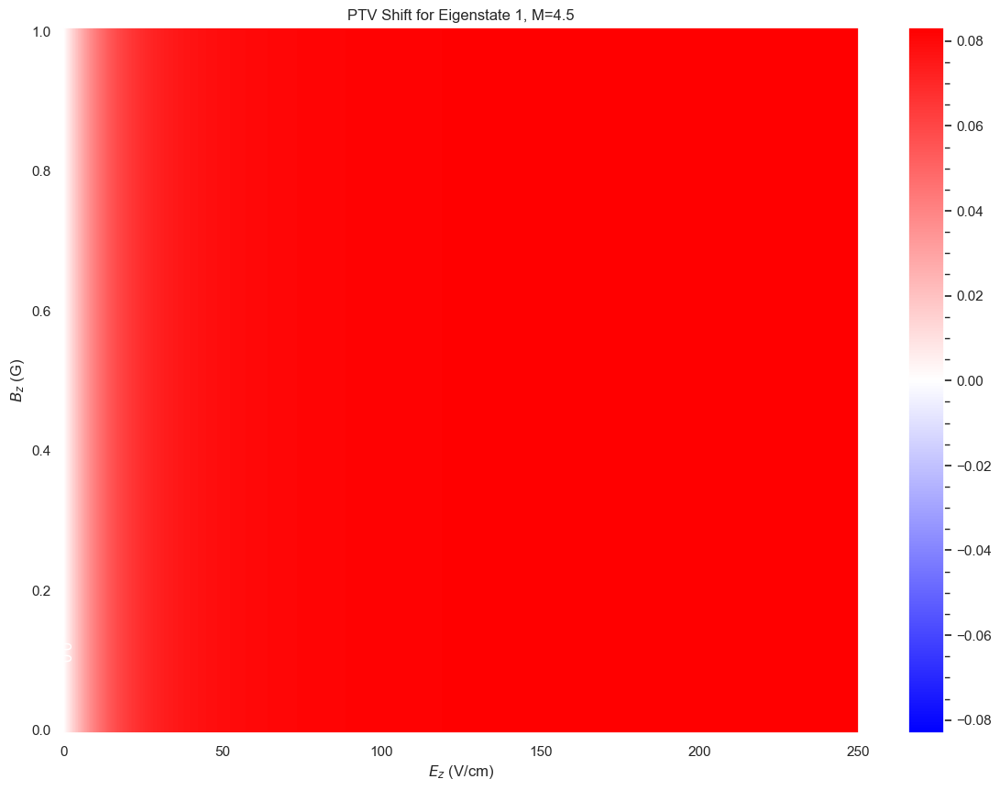

In [11]:
with_contour=True
for M in eval_dict.keys():
    print(M)
    PTV_EB = PTV_dict[M]
    evals_EB = eval_dict[M]
    for i in range(len(PTV_EB)):
        plt.figure(figsize=(14,10))
        geff = np.gradient(evals_EB[i])[1]/abs(Bz[-1]-Bz[-2])
        PTV = PTV_EB[i]
        max_delta = max(abs(PTV.max()),abs(PTV.min()))
        if max_delta==0:
            max_delta=0.01
        plt.grid(False)
        plt.pcolormesh(*mesh,PTV,shading='auto',cmap='bwr',norm=TwoSlopeNorm(vmin=-max_delta,vcenter=0,vmax=max_delta))
        cbar = plt.colorbar()
        cbar.minorticks_on()
        plt.title('PTV Shift for Eigenstate {}, M={}'.format(i,M))
        plt.xlabel(r'$E_z$ (V/cm)')
        plt.ylabel(r'$B_z$ (G)')
        if with_contour:
            try:
                conmap = plt.contour(*mesh,geff/muBgS,colors='black',levels=[-0.1,0,0.1],vmin=-0.1,vmax=0.1)#norm=TwoSlopeNorm(vmin=-1,vcenter=0,vmax=1))
                plt.clabel(conmap, inline=True, fontsize=12)
    #             cbar = plt.colorbar()
    #             cbar.minorticks_on()
            except ValueError:
                print("Can't plot this data")
            try:
                conmap = plt.contour(*mesh,PTV,colors='white',levels=[-0.4,-0.3,-0.2,-0.1,0,0.1,0.2,0.3,0.4],vmin=-0.1,vmax=0.1)#norm=TwoSlopeNorm(vmin=-1,vcenter=0,vmax=1))
                plt.clabel(conmap, inline=True, fontsize=12)
    #             cbar = plt.colorbar()
    #             cbar.minorticks_on()
            except ValueError:
                print("Can't plot this data")

**Not run (port to current API, 2026-10-25).** The raw cells below analyze an integer-M dataset (keys M = -2..2, e.g. `eval_dict[1]`, `eval_dict[-1]`, `state_dict[2]`; bBJ kets with I_H only), from an earlier run of this notebook on a different molecule/grid. This notebook now computes 173YbOH X(010) with M = 1/2..9/2 only (cell above), so these keys do not exist. Source kept unchanged; switch the cell type back to code once that dataset is defined.

In [12]:
evals_EB.shape

(2, 2001, 100)

In [13]:
np.searchsorted(Ez,390)

2001

**Not run (port to current API, 2026-10-25).** The raw cells below analyze an integer-M dataset (keys M = -2..2, e.g. `eval_dict[1]`, `eval_dict[-1]`, `state_dict[2]`; bBJ kets with I_H only), from an earlier run of this notebook on a different molecule/grid. This notebook now computes 173YbOH X(010) with M = 1/2..9/2 only (cell above), so these keys do not exist. Source kept unchanged; switch the cell type back to code once that dataset is defined.

In [14]:
Ez = mesh[0,:,0]
Bz = mesh[1,0,:]

In [15]:
from scipy.optimize import curve_fit

def fitFunction(xscale,data,function,guess,sigma,plot,bounds=None):
    xscale = np.array(xscale)
    data = np.array(data)
    guess = np.array(guess).astype(float)
    if bounds==None:
        bounds = (-np.inf,np.inf)
    try:
        popt,pcov = curve_fit(function,xscale,data,p0=guess,sigma=sigma,bounds=bounds)
        perr = np.round(np.sqrt((np.diag(pcov))),decimals=6)
        params = np.round(popt,decimals=6)
        fit = function(xscale,*popt)
        residuals = data - fit
        if plot:
            plotFitComparison(xscale,data,function,params,sigma)
            plotFitResiduals(xscale,residuals,sigma)
    except RuntimeError:
        print("Error - curve_fit failed")
        print(guess)
        plt.figure()
        plt.plot(xscale,data)
        plt.plot(xscale,function(xscale,*guess))
        params = []
        perr = []
        residuals = []
    return [params,perr,residuals]

def plotFitComparison(xscale,data,function,params,sigma,xlabel=None,ylabel=None):
    plt.figure()
    plt.title('Fit vs Data')
    if sigma is None:
        plt.plot(xscale,data,label='Data',marker='o')
    else:
        plt.errorbar(xscale,data,yerr=sigma,label='Data',marker='o',linestyle='None')
    plt.plot(xscale,function(xscale,*params),label='Fit')
    return

def plotFitResiduals(xscale,residuals,sigma):
    plt.figure()
    plt.title('Fit Residuals')
    if sigma is None:
        plt.plot(xscale,residuals,'o',linestyle='None')
    else:
        plt.errorbar(xscale,residuals,yerr=sigma,marker='o',linestyle='None')
    plt.plot(xscale,np.zeros(len(xscale)),linestyle='--')
    return

def quadratic(x,a,b):
    return a*x**2+b

def line(x,m,b):
    return m*x+b

def fitQuad(xscale, data,guess=[1,0],sigma=None,plot=True,verbose=False):
    function = quadratic
    params,error,residuals = fitFunction(xscale,data,function,guess,sigma,plot)
    if verbose:
        print('a = {} +/- {}'.format(params[0],error[0]))
        print('b = {} +/- {}'.format(params[1],error[1]))
    return [params,error,residuals]

def fitLine(xscale, data,guess=[1,0],sigma=None,plot=True,verbose=False):
    function = line
    params,error,residuals = fitFunction(xscale,data,function,guess,sigma,plot)
    if verbose:
        print('m = {} +/- {}'.format(params[0],error[0]))
        print('b = {} +/- {}'.format(params[1],error[1]))
    return [params,error,residuals]

**Not run (port to current API, 2026-10-25).** The raw cells below analyze an integer-M dataset (keys M = -2..2, e.g. `eval_dict[1]`, `eval_dict[-1]`, `state_dict[2]`; bBJ kets with I_H only), from an earlier run of this notebook on a different molecule/grid. This notebook now computes 173YbOH X(010) with M = 1/2..9/2 only (cell above), so these keys do not exist. Source kept unchanged; switch the cell type back to code once that dataset is defined.

In [16]:
x = np.zeros((100,100))
y = np.zeros((100,100))+1
y[3:5,20:80] = 1

In [17]:
d = x-y
testmesh = np.array(np.meshgrid(np.arange(100),np.arange(100),indexing='ij'))

Text(0, 0.5, '$B_z$ (G)')

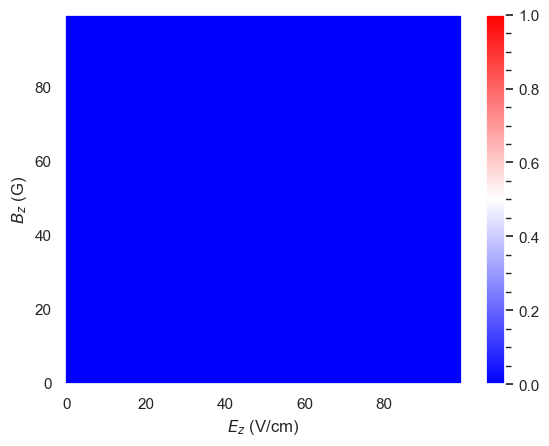

In [18]:
plt.figure()
plt.grid(False)
plt.pcolormesh(*testmesh,abs(d)<0.1,shading='auto',cmap='bwr',vmin=0,vmax=1)
cbar = plt.colorbar()
cbar.minorticks_on()
plt.xlabel(r'$E_z$ (V/cm)')
plt.ylabel(r'$B_z$ (G)')

In [19]:
(abs(d)<0.1).nonzero()[0].size

0

In [20]:
len(eval_dict.keys())

5

In [21]:
muBgS=1.399624494*2.0023/2
Dmol = 2.10*0.503412*1/2
PTVmax = 1/6
E_thresh = 5000
PTV_thresh = 0.05
geff_thresh = 1e-2
Dz_thresh = 0.1
Ez_idx_match = []
Bz_idx_match = []
eigenstate_match = []
M_match = []
M_list = list(eval_dict.keys())
for Midx in range(len(M_list)):
    Mi = M_list[Midx]
    for Mjdx in range(Midx,len(M_list)):
        Mj = M_list[Mjdx]
        if abs(Mi-Mj)>0:
            continue
        else:
            evals_Mi = eval_dict[Mi]
            evals_Mj = eval_dict[Mj]
            PTV_Mi = PTV_dict[Mi]
            PTV_Mj = PTV_dict[Mj]
            for i in range(len(evals_Mi)):
                for j in range(i,len(evals_Mj)):
                    if i==j and Mi==Mj:
                        continue
                    deltaE_ij = evals_Mi[i]-evals_Mj[j]
                    E_bool_match = (abs(deltaE_ij)<E_thresh)
                    if E_bool_match.any():
                        geff_i = np.gradient(evals_Mi[i])[1]/(Bz[1]-Bz[0])/muBgS
                        geff_j = np.gradient(evals_Mj[j])[1]/(Bz[1]-Bz[0])/muBgS
                        deltag_ij = geff_i - geff_j
                        g_bool_match = np.logical_and(abs(deltag_ij)<geff_thresh, E_bool_match)
                        if g_bool_match.any():
                            Dz_i = np.gradient(evals_Mi[i])[0]/(Ez[1]-Ez[0])/Dmol
                            Dz_j = np.gradient(evals_Mi[j])[0]/(Ez[1]-Ez[0])/Dmol
                            deltaDz_ij = Dz_i - Dz_j
                            Dz_bool_match = np.logical_and(abs(deltaDz_ij)<Dz_thresh, g_bool_match)
                            if Dz_bool_match.any():
                                PTV_i = PTV_Mi[i]/PTVmax
                                PTV_j = PTV_Mj[j]/PTVmax
                                deltaPTV_ij = PTV_i - PTV_j
                                PTV_bool_match = np.logical_and(abs(deltaPTV_ij)>PTV_thresh, Dz_bool_match)
                                if PTV_bool_match.any():
                                    #Found a match!
                                    idx_match = PTV_bool_match.nonzero()
                                    print('Found a match!')
                                    if Bz[idx_match[1]].min()>0.1:
                                        print('Match at Bz min = {}, details omitted'.format(Bz[idx_match[1]].min()))
                                    else:
                                        print('i = {}, Mi = {}'.format(i,Mi))
                                        print('j = {}, Mj = {}'.format(j,Mj))
                                        print('Ez vals = {}'.format((Ez[idx_match[0]].min(),Ez[idx_match[0]].max())))
                                        print('Bz vals = {}'.format((Bz[idx_match[1]].min(),Bz[idx_match[1]].max())))
                                        print('delta geff avg = {}'.format(deltag_ij[idx_match].mean()))
                                        print('delta Dz avg = {}'.format(deltaDz_ij[idx_match].mean()))
                                        print('delta PTV avg = {}'.format(deltaPTV_ij[idx_match].mean()))
                                    Ez_idx_match.append(idx_match[0])
                                    Bz_idx_match.append(idx_match[1])
                                    eigenstate_match.append([i,j])
                                    M_match.append([Mi,Mj])

Found a match!
i = 0, Mi = 0.5
j = 2, Mj = 0.5
Ez vals = (5.625, 7.5)
Bz vals = (0.0001, 1.0)
delta geff avg = 0.008317087671970126
delta Dz avg = -0.026720569112563142
delta PTV avg = -0.05535975679235512
Found a match!
Match at Bz min = 0.6566, details omitted
Found a match!
i = 1, Mi = 0.5
j = 2, Mj = 0.5
Ez vals = (7.0, 65.625)
Bz vals = (0.0001, 0.9494999999999999)
delta geff avg = 2.977319330353029e-05
delta Dz avg = -0.0414500362508061
delta PTV avg = -0.08824685664838254
Found a match!
Match at Bz min = 0.5051, details omitted
Found a match!
Match at Bz min = 0.23239999999999997, details omitted
Found a match!
i = 1, Mi = 0.5
j = 6, Mj = 0.5
Ez vals = (51.75, 64.25)
Bz vals = (0.0001, 0.2627)
delta geff avg = 0.008857546925730158
delta Dz avg = -0.03816504455132249
delta PTV avg = -0.05882767433728223
Found a match!
i = 1, Mi = 0.5
j = 7, Mj = 0.5
Ez vals = (21.25, 28.5)
Bz vals = (0.0001, 1.0)
delta geff avg = 0.0005329656718586962
delta Dz avg = -0.08338015992868737
delta PTV

Found a match!
i = 2, Mi = 0.5
j = 7, Mj = 0.5
Ez vals = (24.75, 34.0)
Bz vals = (0.0001, 1.0)
delta geff avg = -0.0027059753937788765
delta Dz avg = -0.02839981159520663
delta PTV avg = -0.055362086386320765
Found a match!
i = 2, Mi = 0.5
j = 8, Mj = 0.5
Ez vals = (24.25, 31.5)
Bz vals = (0.0001, 1.0)
delta geff avg = 9.437663550374859e-05
delta Dz avg = -0.0689155298239574
delta PTV avg = 0.06518401285332405
Found a match!
Match at Bz min = 0.293, details omitted
Found a match!
i = 2, Mi = 0.5
j = 10, Mj = 0.5
Ez vals = (26.375, 34.25)
Bz vals = (0.0001, 1.0)
delta geff avg = 4.6215707362069517e-05
delta Dz avg = -0.07859688459042688
delta PTV avg = 0.08073331101289738
Found a match!
i = 2, Mi = 0.5
j = 11, Mj = 0.5
Ez vals = (19.5, 37.0)
Bz vals = (0.0506, 1.0)
delta geff avg = 0.0006479145987089584
delta Dz avg = -0.07591517500437679
delta PTV avg = 0.07672370018697433
Found a match!
i = 3, Mi = 0.5
j = 4, Mj = 0.5
Ez vals = (206.75, 213.125)
Bz vals = (0.0001, 1.0)
delta geff avg 

Found a match!
i = 5, Mi = 0.5
j = 6, Mj = 0.5
Ez vals = (7.0, 65.25)
Bz vals = (0.0001, 1.0)
delta geff avg = -0.0025517607196142017
delta Dz avg = -0.04879289213731778
delta PTV avg = -0.09277841383460789
Found a match!
i = 5, Mi = 0.5
j = 7, Mj = 0.5
Ez vals = (6.625, 9.625)
Bz vals = (0.0001, 1.0)
delta geff avg = -0.007625017794280416
delta Dz avg = -0.02923857584274722
delta PTV avg = -0.05887589387269985
Found a match!
i = 6, Mi = 0.5
j = 9, Mj = 0.5
Ez vals = (14.5, 21.625)
Bz vals = (0.0001, 0.18189999999999998)
delta geff avg = -0.00627418307942202
delta Dz avg = -0.032453703093763206
delta PTV avg = 0.05583979478383839
Found a match!
i = 6, Mi = 0.5
j = 11, Mj = 0.5
Ez vals = (12.5, 19.0)
Bz vals = (0.0001, 0.18189999999999998)
delta geff avg = -0.006186472097150665
delta Dz avg = -0.026265102105591385
delta PTV avg = 0.057298415205235605
Found a match!
i = 7, Mi = 0.5
j = 8, Mj = 0.5
Ez vals = (13.25, 47.375)
Bz vals = (0.0001, 1.0)
delta geff avg = 0.00015014398209393343
d

Found a match!
i = 12, Mi = 0.5
j = 14, Mj = 0.5
Ez vals = (1.125, 3.0)
Bz vals = (0.0001, 1.0)
delta geff avg = -0.005857869548528145
delta Dz avg = -0.028033450820954573
delta PTV avg = 0.0770792861728223
Found a match!
Match at Bz min = 0.7273, details omitted
Found a match!
i = 12, Mi = 0.5
j = 21, Mj = 0.5
Ez vals = (3.0, 4.75)
Bz vals = (0.0001, 0.060700000000000004)
delta geff avg = -0.006757649521372102
delta Dz avg = -0.03145146256386822
delta PTV avg = 0.06176011693770492
Found a match!
i = 12, Mi = 0.5
j = 23, Mj = 0.5
Ez vals = (4.125, 5.125)
Bz vals = (0.0001, 0.0405)
delta geff avg = -0.007827635555841204
delta Dz avg = -0.04398905752917615
delta PTV avg = 0.05582850514615385
Found a match!
i = 13, Mi = 0.5
j = 14, Mj = 0.5
Ez vals = (1.25, 250.0)
Bz vals = (0.0001, 1.0)
delta geff avg = -0.004335317083839173
delta Dz avg = 0.014512455246860718
delta PTV avg = 0.07068945912372171
Found a match!
i = 13, Mi = 0.5
j = 15, Mj = 0.5
Ez vals = (1.0, 3.0)
Bz vals = (0.0001, 1.0)

Found a match!
i = 14, Mi = 0.5
j = 17, Mj = 0.5
Ez vals = (8.5, 21.875)
Bz vals = (0.0001, 1.0)
delta geff avg = 0.0003650641975904134
delta Dz avg = 0.07175629084226585
delta PTV avg = -0.18514392879366393
Found a match!
Match at Bz min = 0.8686999999999999, details omitted
Found a match!
Match at Bz min = 0.5758, details omitted
Found a match!
i = 14, Mi = 0.5
j = 20, Mj = 0.5
Ez vals = (8.75, 13.5)
Bz vals = (0.0001, 1.0)
delta geff avg = -9.27992430744791e-05
delta Dz avg = 0.0060528541462882245
delta PTV avg = -0.10359752100367253
Found a match!
i = 14, Mi = 0.5
j = 21, Mj = 0.5
Ez vals = (4.25, 18.5)
Bz vals = (0.0506, 1.0)
delta geff avg = 0.0003275460450713338
delta Dz avg = 0.00129097755510222
delta PTV avg = -0.09575443556992483
Found a match!
i = 14, Mi = 0.5
j = 22, Mj = 0.5
Ez vals = (9.5, 14.625)
Bz vals = (0.0001, 1.0)
delta geff avg = 2.840002792544488e-05
delta Dz avg = -0.00905017440175974
delta PTV avg = -0.14586842928245056
Found a match!
i = 14, Mi = 0.5
j = 23, M

Found a match!
i = 17, Mi = 0.5
j = 19, Mj = 0.5
Ez vals = (3.875, 7.875)
Bz vals = (0.0001, 1.0)
delta geff avg = 0.006082767144929994
delta Dz avg = -0.025012088060207955
delta PTV avg = 0.07313832825971438
Found a match!
i = 17, Mi = 0.5
j = 20, Mj = 0.5
Ez vals = (6.25, 12.625)
Bz vals = (0.0001, 0.2425)
delta geff avg = 0.00394705633457982
delta Dz avg = -0.05428500859045277
delta PTV avg = 0.06730468550855614
Found a match!
i = 17, Mi = 0.5
j = 22, Mj = 0.5
Ez vals = (10.75, 14.75)
Bz vals = (0.0001, 0.22229999999999997)
delta geff avg = 0.00255190739064996
delta Dz avg = -0.08842998129603727
delta PTV avg = 0.055533082756476684
Found a match!
i = 19, Mi = 0.5
j = 20, Mj = 0.5
Ez vals = (9.5, 42.625)
Bz vals = (0.0001, 0.43439999999999995)
delta geff avg = 0.0007581513840163762
delta Dz avg = -0.021635238433534744
delta PTV avg = -0.15685127841612947
Found a match!
i = 19, Mi = 0.5
j = 21, Mj = 0.5
Ez vals = (11.125, 20.625)
Bz vals = (0.0001, 1.0)
delta geff avg = -0.00031971366

... (4 outputs left out)

Found a match!
Match at Bz min = 0.5253, details omitted
Found a match!
Match at Bz min = 0.5253, details omitted
Found a match!
i = 17, Mi = 1.5
j = 21, Mj = 1.5
Ez vals = (166.5, 192.625)
Bz vals = (0.0001, 1.0)
delta geff avg = 0.00010444096337533061
delta Dz avg = -0.030677976003184
delta PTV avg = -1.2861658674358905
Found a match!
i = 18, Mi = 1.5
j = 20, Mj = 1.5
Ez vals = (4.875, 7.625)
Bz vals = (0.0001, 1.0)
delta geff avg = -0.007511773707209965
delta Dz avg = -0.027248070348524767
delta PTV avg = -0.05844000681111924
Found a match!
i = 19, Mi = 1.5
j = 21, Mj = 1.5
Ez vals = (3.75, 7.625)
Bz vals = (0.0001, 1.0)
delta geff avg = 0.006535922271401462
delta Dz avg = -0.04432759836922781
delta PTV avg = -0.07011896844117646
Found a match!
i = 0, Mi = 2.5
j = 1, Mj = 2.5
Ez vals = (1.75, 3.375)
Bz vals = (0.0001, 1.0)
delta geff avg = -0.00099197691773461
delta Dz avg = -0.07576061598476877
delta PTV avg = -0.07624547293242857
Found a match!
Match at Bz min = 0.3334, details om

Found a match!
i = 2, Mi = 2.5
j = 3, Mj = 2.5
Ez vals = (127.125, 128.5)
Bz vals = (0.0001, 1.0)
delta geff avg = -7.307279466456081e-06
delta Dz avg = -0.02782653866569599
delta PTV avg = 0.1796912387552632
Found a match!
i = 2, Mi = 2.5
j = 4, Mj = 2.5
Ez vals = (1.25, 1.625)
Bz vals = (0.0001, 1.0)
delta geff avg = 0.0007964049171388592
delta Dz avg = -0.08416511660254962
delta PTV avg = -0.058092404149118385
Found a match!
Match at Bz min = 0.9697, details omitted
Found a match!
i = 2, Mi = 2.5
j = 8, Mj = 2.5
Ez vals = (107.0, 117.375)
Bz vals = (0.0001, 1.0)
delta geff avg = -0.0019264260854708378
delta Dz avg = 0.05180898707049636
delta PTV avg = 0.5856611817301849
Found a match!
Match at Bz min = 0.9494999999999999, details omitted
Found a match!
i = 3, Mi = 2.5
j = 5, Mj = 2.5
Ez vals = (1.5, 2.5)
Bz vals = (0.0001, 1.0)
delta geff avg = -0.0017702217082093646
delta Dz avg = -0.08045356769858084
delta PTV avg = -0.06720770299443038
Found a match!
i = 3, Mi = 2.5
j = 8, Mj = 2

Found a match!
i = 10, Mi = 2.5
j = 12, Mj = 2.5
Ez vals = (1.0, 2.5)
Bz vals = (0.0001, 1.0)
delta geff avg = -0.00033072659994174764
delta Dz avg = -0.06929699902475521
delta PTV avg = 0.08549330877311204
Found a match!
i = 11, Mi = 2.5
j = 13, Mj = 2.5
Ez vals = (0.875, 1.375)
Bz vals = (0.0001, 1.0)
delta geff avg = 0.0019131057987745903
delta Dz avg = -0.07787165353983184
delta PTV avg = 0.0742301956332
Found a match!
i = 12, Mi = 2.5
j = 15, Mj = 2.5
Ez vals = (175.75, 202.375)
Bz vals = (0.0001, 1.0)
delta geff avg = -1.9683845570260364e-05
delta Dz avg = -0.05299156952708246
delta PTV avg = -1.2799170681709882
Found a match!
i = 14, Mi = 2.5
j = 15, Mj = 2.5
Ez vals = (3.375, 9.5)
Bz vals = (0.0001, 1.0)
delta geff avg = 0.0006260351601113833
delta Dz avg = -0.06766775765363515
delta PTV avg = -0.09752340808212
Found a match!
i = 1, Mi = 3.5
j = 3, Mj = 3.5
Ez vals = (1.125, 1.25)
Bz vals = (0.0001, 1.0)
delta geff avg = -0.0005023590051762566
delta Dz avg = -0.0885981771667274

Found a match!
i = 4, Mi = 3.5
j = 5, Mj = 3.5
Ez vals = (16.0, 20.125)
Bz vals = (0.0001, 1.0)
delta geff avg = -0.00022044486557572815
delta Dz avg = -0.08991981096386817
delta PTV avg = 0.05634534250718797
Found a match!
i = 6, Mi = 3.5
j = 7, Mj = 3.5
Ez vals = (0.75, 1.25)
Bz vals = (0.0001, 1.0)
delta geff avg = 0.0013979351352721592
delta Dz avg = -0.07651886158197556
delta PTV avg = 0.07000396513320001


In [22]:
Bz[Bz_idx_match[0]].min

<function ndarray.min>

**Not run (port to current API, 2026-10-25).** The raw cells below analyze an integer-M dataset (keys M = -2..2, e.g. `eval_dict[1]`, `eval_dict[-1]`, `state_dict[2]`; bBJ kets with I_H only), from an earlier run of this notebook on a different molecule/grid. This notebook now computes 173YbOH X(010) with M = 1/2..9/2 only (cell above), so these keys do not exist. Source kept unchanged; switch the cell type back to code once that dataset is defined.

In [23]:
Em = np.searchsorted(Ez,40)
Em

320

**Not run (port to current API, 2026-10-25).** The raw cells below analyze an integer-M dataset (keys M = -2..2, e.g. `eval_dict[1]`, `eval_dict[-1]`, `state_dict[2]`; bBJ kets with I_H only), from an earlier run of this notebook on a different molecule/grid. This notebook now computes 173YbOH X(010) with M = 1/2..9/2 only (cell above), so these keys do not exist. Source kept unchanged; switch the cell type back to code once that dataset is defined.

In [24]:
np.linspace(-0.1,0.1,21)

array([-0.1 , -0.09, -0.08, -0.07, -0.06, -0.05, -0.04, -0.03, -0.02,
       -0.01,  0.  ,  0.01,  0.02,  0.03,  0.04,  0.05,  0.06,  0.07,
        0.08,  0.09,  0.1 ])

**Not run (port to current API, 2026-10-25).** The raw cells below analyze an integer-M dataset (keys M = -2..2, e.g. `eval_dict[1]`, `eval_dict[-1]`, `state_dict[2]`; bBJ kets with I_H only), from an earlier run of this notebook on a different molecule/grid. This notebook now computes 173YbOH X(010) with M = 1/2..9/2 only (cell above), so these keys do not exist. Source kept unchanged; switch the cell type back to code once that dataset is defined.